# Backpropagation and PyTorch

*Tutorial by Yuan-Sen Ting (ting.74@osu.edu)*

*Companion material for Chapter 15 of the textbook*

*If you find this tutorial useful, please cite the accompanying textbook.*

*[Statistical Machine Learning for Astronomy](https://ui.adsabs.harvard.edu/abs/2025arXiv250612230T/abstract)*

*© 2025 Yuan-Sen Ting. All rights reserved. This tutorial may be redistributed by sharing the original [website page link](https://tingyuansen.github.io/statml/) for educational purposes. Any other reproduction or adaptation requires explicit permission from the author.*

## Introduction

Modern deep learning models are trained with gradient descent (Section 15.3). Each step needs the gradient of the loss with respect to every weight. A network can have very many weights, so we need an efficient way to compute all of these gradients.

Backpropagation gives all gradients from one forward pass and one backward pass through the network (Section 15.4). The backward pass applies the chain rule layer by layer and reuses the numbers of the forward pass. Symbolic differentiation returns a formula that grows with every layer. Finite differences estimate each derivative from a small change of one weight, so they need one extra forward pass for each weight. Automatic differentiation libraries such as PyTorch apply the same idea to any model that we write with differentiable operations.

In this tutorial we write backpropagation in NumPy for a network with one hidden layer. The network fits a noisy cubic polynomial. We check its gradients against those of PyTorch and then train the same network with PyTorch. We also compare two optimizers, stochastic gradient descent and Adam (Section 15.3), and a learning rate schedule. Last, we meet the ReLU activation and the He initialization of the weights.


## Prerequisites and Learning Objectives

### Prerequisites

This tutorial assumes the following.

- Python programming, with NumPy arrays, matplotlib plots and classes
- Neural networks, with the forward pass, activation functions and loss functions (Chapter 15)
- Gradient descent, with the loss and the learning rate (Chapter 7)
- Matrix multiplication and the chain rule from multivariable calculus

### Learning Objectives

After this tutorial you can do the following.

- Implement the forward and backward passes of a network with one hidden layer in NumPy
- Check the gradients of your own backward pass against automatic differentiation
- Explain how PyTorch records a computational graph, and how automatic differentiation differs from symbolic differentiation and finite differences
- Train a network with PyTorch, use mini-batches, compare gradient descent with Adam and use a cosine learning rate schedule
- Use ReLU and GELU in PyTorch and explain the He initialization
- Describe how to run PyTorch code on a GPU

## Understanding Backpropagation Through Implementation

We first write backpropagation in NumPy, so that we see each step of the algorithm before we use a library.

Gradient descent needs the gradient of the loss with respect to every weight (Section 15.3). A neural network is a nested function, a chain of simple steps, so the chain rule gives these gradients (Section 15.4). Consider a tiny chain, $z = 3x + 1$ followed by $L = z^2$.

In the forward pass we compute $z$ and then $L$, and we keep the value of $z$. In the backward pass we start from the loss and work back. The derivative of $L$ with respect to $z$ is $2z$, and the derivative of $z$ with respect to $x$ is 3. The chain rule multiplies them, so $\partial L/\partial x = 2z \times 3$. Each step needs only its own derivative and the value that the forward pass kept.

Backpropagation does the same for a whole network. The forward pass computes the output and stores the intermediate values. The backward pass multiplies the local derivatives with the chain rule, from the loss back to each weight.

We build the network from three kinds of components. They are a fully connected layer, an activation function and a loss function. Each component has three methods.

1. The forward pass computes the output and caches the values that the backward pass needs.
2. The backward pass receives the gradient of the loss with respect to the output of the component. It returns the gradient with respect to its input and computes the gradients of its own parameters.
3. The update changes the parameters of the component (if it has any) with their gradients.

Gradients flow backward through the components, and each component multiplies by its local derivative.

We begin by importing the libraries and setting the plot style.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Set the plot style
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=['#3468A8', '#E49A3A', '#2E8B6E', '#C24A3E', '#6F5E9E', '#8A8A8A'])
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['DejaVu Serif'], 'mathtext.fontset': 'cm'})
plt.rcParams.update({'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True})

# Set random seed for reproducibility
np.random.seed(42)

%matplotlib inline

### Constructing the Fully Connected Layer

We begin with the fully connected layer, also called the linear layer. It mixes all inputs into each output with the operation $\mathbf{z} = \mathbf{W}\mathbf{x} + \mathbf{b}$ (Section 15.1). Here $\mathbf{W}$ is the weight matrix of shape (`out_features`, `in_features`) and $\mathbf{b}$ is the bias vector. The code processes a batch of points at once, which is the set of points that we handle together. The batch array has one row for each point, so the code computes the same operation for all points as $\mathbf{X}\mathbf{W}^T + \mathbf{b}^T$.

The method `init_weights` sets the weights to random numbers from a standard normal distribution and the biases to zero. The weights start at random values so that the hidden units differ, because equal weights would give units that stay equal.

In [2]:
class FullyConnectedLayer:
    """
    Fully connected (linear) layer, z = Wx + b for each input x.

    The inputs of a batch are the rows of X, so the layer computes X W^T + b^T.
    It caches the input in the forward pass and uses it in the backward pass.
    """
    def __init__(self, in_features, out_features):
        self.in_features = in_features
        self.out_features = out_features

        # Initialize parameters, W has the shape (out_features, in_features) as in the textbook
        self.weight = np.zeros((out_features, in_features))
        self.bias = np.zeros((out_features, 1))

        # Storage for gradients
        self.g_weight = np.zeros((out_features, in_features))
        self.g_bias = np.zeros((out_features, 1))

        # Cache for input (needed for backward pass)
        self.input = None

    def init_weights(self):
        """Initialize the weights from a standard normal distribution and the biases at zero."""
        self.weight = np.random.randn(self.out_features, self.in_features)
        self.bias = np.zeros((self.out_features, 1))

    def forward_pass(self, X):
        """Forward propagation, z = Wx + b, for X of shape (batch_size, in_features)."""
        self.input = X  # Cache input for backward pass
        out = np.dot(X, self.weight.T) + self.bias.T  # The bias row is added to every input
        return out

    def backward_pass(self, g_next_layer):
        """Backward propagation, from dL/dz of shape (batch_size, out_features) to dL/dx."""

        # Gradient with respect to the weights, the sum over the batch of (dL/dz)^T x^T
        self.g_weight = np.dot(g_next_layer.T, self.input)

        # Gradient with respect to the bias, the sum of dL/dz over the batch
        self.g_bias = np.sum(g_next_layer, axis=0).reshape(-1, 1)

        # Gradient with respect to the input, (dL/dz) W for each point
        g_last_layer = np.dot(g_next_layer, self.weight)

        return g_last_layer

    def update(self, learning_rate):
        """Update parameters using gradient descent."""
        self.weight -= learning_rate * self.g_weight
        self.bias -= learning_rate * self.g_bias


### Understanding the Fully Connected Layer Operations

The forward pass computes $\mathbf{z}$ and caches the input $\mathbf{x}$. We evaluate a gradient at a specific point. The backward pass therefore needs the values of the forward pass (Section 15.4). The cache saves us from computing them again.

The backward pass receives the row $\partial L/\partial \mathbf{z}$ from the next layer, as in Section 15.4. The local derivatives of $\mathbf{z} = \mathbf{W}\mathbf{x} + \mathbf{b}$ are $\mathbf{x}^T$ for the weights of one unit, 1 for the bias and $\mathbf{W}$ for the input. The chain rule multiplies each of them by $\partial L/\partial \mathbf{z}$ and gives three gradients.

1. The gradient with respect to the weights is $\partial L/\partial \mathbf{W} = (\partial L/\partial \mathbf{z})^T \mathbf{x}^T$, the outer product of a column and a row, summed over the batch.
2. The gradient with respect to the bias is $\partial L/\partial \mathbf{b} = \partial L/\partial \mathbf{z}$, summed over the batch. The code stores it as a column, like $\mathbf{b}$.
3. The gradient with respect to the input is $\partial L/\partial \mathbf{x} = (\partial L/\partial \mathbf{z})\,\mathbf{W}$.

The weights and the bias act on every point of the batch, so their gradients add the contributions of all points. The layer passes the third gradient to the previous layer. This is how gradients flow backward through the whole network.

In the code, each row of the array `g_next_layer` is the row $\partial L/\partial \mathbf{z}$ of one point. The product $(\partial L/\partial \mathbf{Z})^T \mathbf{X}$ gives the weight gradient and sums over the batch, and $(\partial L/\partial \mathbf{Z})\,\mathbf{W}$ gives the input gradient of every point.


### Implementing the Sigmoid Activation Function

We implement the sigmoid activation function $\sigma(z) = 1/(1 + e^{-z})$ (Section 15.5). Without activation functions, a stack of layers would collapse into one linear map. Activation functions make the network nonlinear, so that it can learn complex functions. The derivative of the sigmoid is $\sigma'(z) = \sigma(z)(1 - \sigma(z))$, so it depends only on the output. The layer therefore caches its output and computes the derivative from it, without the original input.

In [3]:
class Sigmoid:
    """
    Sigmoid activation function, σ(z) = 1/(1 + exp(-z)).

    Its derivative σ(z)(1 - σ(z)) depends only on the output.
    """
    def __init__(self):
        self.input = None
        self.output = None

    def forward_pass(self, X):
        """Forward propagation, the sigmoid applied element-wise."""
        self.input = X
        self.output = 1 / (1 + np.exp(-X))
        return self.output

    def backward_pass(self, g_next_layer):
        """Backward propagation, dL/dz = dL/dσ * σ(z)(1 - σ(z))."""

        # Sigmoid derivative, computed from the cached output
        sigmoid_derivative = self.output * (1 - self.output)

        # Apply chain rule, multiply incoming gradient by local derivative
        g_last_layer = g_next_layer * sigmoid_derivative

        return g_last_layer

    def update(self, learning_rate):
        """Activation functions have no parameters to update."""
        pass

In the backward pass the sigmoid receives the gradient $\partial L/\partial a$ with respect to its output $a = \sigma(z)$ from the next layer. The chain rule gives the gradient with respect to its input, $\partial L/\partial z = \sigma'(z)\,\partial L/\partial a$, so the sigmoid multiplies the gradient by $\sigma'(z)$. This factor is at most 0.25, which it reaches when the output is 0.5. It is close to zero when the output is near 0 or 1, where the sigmoid saturates. Each sigmoid layer therefore shrinks the gradient that flows back to the earlier layers, and the shrinking compounds over many layers. This is the vanishing gradient problem (Section 15.5).

### Implementing the Mean Squared Error Loss

We need a loss function to complete the components. We use the mean squared error (MSE) of Section 15.3, which follows from maximum likelihood under Gaussian noise.

$$
L = \frac{1}{N} \sum_{i=1}^{N} (\hat{y}_i - y_i)^2.
$$

Here $\hat{y}_i$ is the prediction of the network and $y_i$ is the target of point $i$.

In [4]:
class MSELoss:
    """
    Mean squared error loss, L = (1/N) Σ(y_pred - y_true)².

    It gives the starting gradient for backpropagation.
    """
    def __init__(self):
        self.y_pred = None
        self.y_true = None
        self.batch_size = None

    def forward_pass(self, y_pred, y_true):
        """Return the mean squared error, averaged over the batch."""

        # Make sure y_true has the shape (batch_size, 1)
        if len(y_true.shape) == 1:
            y_true = y_true[:, np.newaxis]

        self.y_pred = y_pred
        self.y_true = y_true
        self.batch_size = y_pred.shape[0]

        # Compute squared differences
        squared_errors = (y_pred - y_true) ** 2

        # Return mean over all elements
        return np.mean(squared_errors)

    def backward_pass(self, g_next_layer=1):
        """Return the gradient of the loss, dL/dy_pred = 2 (y_pred - y_true) / N."""

        # Gradient of MSE, dL/dy = 2(y_pred - y_true) / N
        g_last_layer = 2 * (self.y_pred - self.y_true) / self.batch_size * g_next_layer

        return g_last_layer

    def update(self, learning_rate):
        """Loss functions have no parameters to update."""
        pass

### Understanding the Loss Function's Role in Backpropagation

The loss function starts the backward pass. Differentiating the MSE gives

$$
\frac{\partial L}{\partial \hat{y}_i} = \frac{2}{N} (\hat{y}_i - y_i).
$$

Section 15.4 writes the loss of one example as $(1/2)(y - \hat{y})^2$. Its gradient has the factor 1 where ours has the factor $2/N$. The loss is a scalar, and its derivative with respect to itself is 1. The argument `g_next_layer` of the loss therefore defaults to 1. The factor $1/N$ keeps the size of the gradient from growing with the number of points.

### Assembling a Complete Neural Network

We now chain the components into a network with one hidden layer of configurable size. The forward pass runs the components in order, and the backward pass runs them in reverse order.

In [5]:
class Network:
    """
    Neural network with the architecture Input → FC → Sigmoid → FC → Output.

    The forward pass runs the layers in order and the backward pass runs them in reverse.
    """
    def __init__(self, input_dim=1, hidden_dim=10, output_dim=1):
        self.layers = []

        # Build the network architecture
        # Layer 1, fully connected from input_dim to hidden_dim
        fc1 = FullyConnectedLayer(input_dim, hidden_dim)
        fc1.init_weights()
        self.layers.append(fc1)

        # Activation, sigmoid only in the hidden layer
        sigmoid = Sigmoid()
        self.layers.append(sigmoid)

        # Layer 2, fully connected from hidden_dim to output_dim
        fc2 = FullyConnectedLayer(hidden_dim, output_dim)
        fc2.init_weights()
        self.layers.append(fc2)

    def forward_pass(self, X):
        """Forward propagation through the entire network."""
        output = X
        for layer in self.layers:
            output = layer.forward_pass(output)
        return output

    def backward_pass(self, grad):
        """Backward propagation through the entire network."""

        # Pass gradient backward through layers in reverse order
        for layer in reversed(self.layers):
            grad = layer.backward_pass(grad)

    def update(self, learning_rate):
        """Update all trainable parameters in the network."""
        for layer in self.layers:
            layer.update(learning_rate)

### Understanding the Network Architecture

The network maps the input through a hidden layer with a sigmoid and a linear output layer to one output value.

1. **Hidden layer.** Each hidden unit applies a sigmoid to a linear function of the input. It adds one smooth step to the output function (Section 15.2).
2. **Linear output layer.** The output is a linear combination of the hidden units, so it can take any real value, which regression needs.


### Training on Simulated Data

We now train the network on simulated data. The 200 points $x$ are uniform on $(-2, 2)$. The target is $y = 0.5x^3 - 0.3x^2 + 0.8x + 0.2$ plus Gaussian noise of standard deviation 0.1. We split the points at random into 160 training points and 40 test points. The test points take no part in the training.

In [6]:
# Generate simulated data with train/test split
# Create data
n_samples = 200
X_all = np.random.uniform(-2, 2, (n_samples, 1))

# Generate target data, a cubic polynomial with some noise
# y = 0.5x³ - 0.3x² + 0.8x + 0.2
coefficients = [0.5, -0.3, 0.8, 0.2]
y_all = (coefficients[0] * X_all**3 +
         coefficients[1] * X_all**2 +
         coefficients[2] * X_all +
         coefficients[3])
y_all += 0.1 * np.random.randn(n_samples, 1)  # Add Gaussian noise

# Split into training and test sets (80/20 split)
n_train = int(0.8 * n_samples)
indices = np.random.permutation(n_samples)  # Random order of the points
train_idx, test_idx = indices[:n_train], indices[n_train:]

# Select the training and test points
X_train, X_test = X_all[train_idx], X_all[test_idx]
y_train, y_test = y_all[train_idx], y_all[test_idx]


### Training and Monitoring the Network

We train a network with 20 hidden units by gradient descent with the learning rate $\eta = 0.03$ (Section 15.3). One epoch is one pass through the training points. Here it is one gradient step, because we use all points at once. Plain gradient descent with a small step needs many epochs, so we train for 100,000 epochs.

Each epoch has four steps.

1. Run the forward pass on the training points and compute their loss.
2. Run the backward pass to get the gradients.
3. Compute the loss of the test points with the same weights, those before the update.
4. Update the weights with the gradients.

The test loss only monitors the training. The update of each layer is

$$
\mathbf{W} \leftarrow \mathbf{W} - \eta \frac{\partial L}{\partial \mathbf{W}},
$$

and the same for the biases.

In [7]:
# Initialize the network and loss function
network = Network(input_dim=1, hidden_dim=20, output_dim=1)
mse_loss = MSELoss()

# Training hyperparameters
learning_rate = 0.03
n_epochs = 100000

# Storage for the training progress
train_loss_history = []
test_loss_history = []

# Training loop
for epoch in range(n_epochs):
    # Forward pass on training data
    y_pred_train = network.forward_pass(X_train)

    # Compute training loss
    train_loss = mse_loss.forward_pass(y_pred_train, y_train)
    train_loss_history.append(train_loss)

    # Backward pass to compute gradients
    grad = mse_loss.backward_pass()
    network.backward_pass(grad)

    # Evaluate on test set with the same weights (no gradient computation needed)
    # This pass overwrites the cached values, so it must follow the backward pass
    y_pred_test = network.forward_pass(X_test)
    test_loss = mse_loss.forward_pass(y_pred_test, y_test)
    test_loss_history.append(test_loss)

    # Update parameters
    network.update(learning_rate)

# Final losses
print(f"Final losses: training {train_loss_history[-1]:.4f}, test {test_loss_history[-1]:.4f}")

Final losses: training 0.0105, test 0.0093


### Visualizing the Training Results

We plot the two losses against the epoch. We also plot the fitted function on a fine grid of inputs, together with the data and the true cubic.

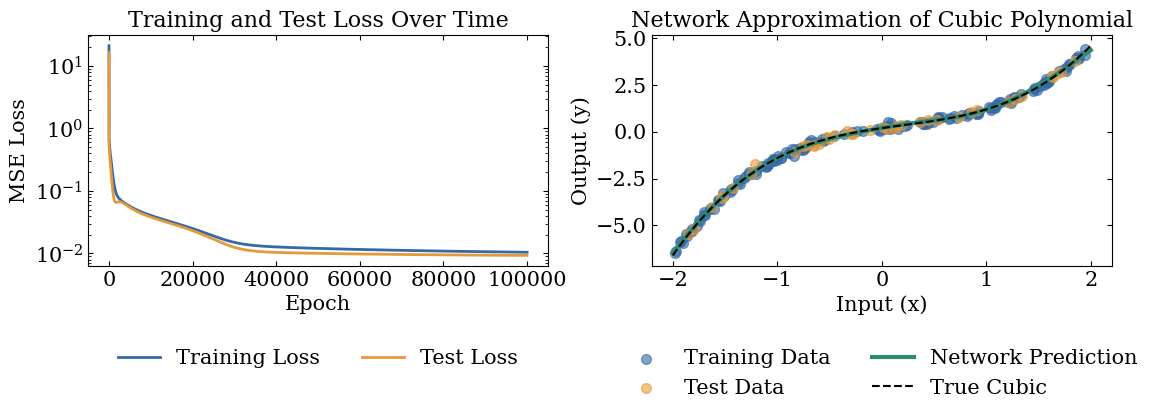

In [8]:
# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

# Left panel, training and test loss history
ax1.plot(train_loss_history, linewidth=2, color='C0', label='Training Loss')
ax1.plot(test_loss_history, linewidth=2, color='C1', label='Test Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('MSE Loss')
ax1.set_title('Training and Test Loss Over Time')
ax1.set_yscale('log')
ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.28), ncol=2)

# Right panel, final predictions and data
# Generate smooth predictions for visualization
X_plot = np.linspace(-2, 2, 200).reshape(-1, 1)  # Column of 200 inputs
y_pred_plot = network.forward_pass(X_plot)

# Data and network prediction
ax2.scatter(X_train, y_train, alpha=0.6, s=50, color='C0', label='Training Data')
ax2.scatter(X_test, y_test, alpha=0.6, s=50, color='C1', label='Test Data')
ax2.plot(X_plot, y_pred_plot, linewidth=3, color='C2', label='Network Prediction')

# True cubic polynomial, the highest power first in np.polyval
ax2.plot(X_plot, np.polyval(coefficients, X_plot), '--', linewidth=1.5, color='black', label='True Cubic')
ax2.set_xlabel('Input (x)')
ax2.set_ylabel('Output (y)')
ax2.set_title('Network Approximation of Cubic Polynomial')
ax2.legend(loc='upper center', bbox_to_anchor=(0.5, -0.28), ncol=2)

plt.tight_layout()
plt.show()

The loss falls quickly in the first epochs and then slowly. The test loss is a little below the training loss, so the network does not overfit. An overfit network fits the training points better than new points. The noise has the variance $0.1^2 = 0.01$, which is the loss that the true cubic gives on average. Both final losses are close to this value. The fitted function follows the cubic over the range of the data.

Our task was regression, one of the two main kinds of supervised task. The other is classification, which assigns an object to a class, such as a star or a galaxy. The output layer depends on the task (Section 15.5), and regression needs outputs that can be any real number, so ours is linear. For two classes, the output is a probability between 0 and 1, so we apply the sigmoid. For several classes, we apply the softmax, so that the probabilities sum to one. The loss changes too, from the mean squared error for regression to the cross-entropy for classification (Section 15.3).

Our fit is also an example of a general result. One hidden layer can approximate any continuous function on a closed, bounded interval to arbitrary accuracy (Section 15.2). It needs enough hidden units and an activation that is not a polynomial.

Every gradient in this network came from the local derivatives of its components, multiplied in reverse order, which is backpropagation. A backward method for every component of every model is a lot of work, so libraries automate it. PyTorch is such a library.

## Automatic Differentiation with PyTorch

PyTorch builds the backward pass from the operations of the forward pass, so we write only the forward pass. We start with tensors, build our network from PyTorch modules and check its gradients against the NumPy ones. We then train it with optimizers and a learning rate schedule, and we end with activation functions, the initial weights and the GPU. We first import PyTorch and set its random seed.

In [9]:
# Import PyTorch and its modules for networks and optimizers
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset  # Mini-batches of the data

# Set random seed for reproducibility
_ = torch.manual_seed(42)


### PyTorch Tensors and Automatic Differentiation

PyTorch tensors are the basic data structure. They are similar to NumPy arrays, but they support automatic differentiation. Each operation on a tensor stores two things, its value and the means to compute its gradient. A tensor that we create with `requires_grad=True` starts to record the computational graph that the differentiation needs. It then carries four pieces of information.

1. **The data values**, as in a NumPy array.
2. **The gradient**, which `backward()` stores in the `.grad` attribute of the tensors that we create.
3. **The graph connectivity**, which means the references to the operations that created the tensor.
4. **The backward function**, which computes the local derivative, like our `backward_pass` methods.

We start with the gradient of $f(x) = x^2$ at $x = 3$ and compare it with the exact derivative $2x$.

In [10]:
# Compute the gradient of f(x) = x^2 at x = 3

# Create a tensor that records its operations
x = torch.tensor([3.0], requires_grad=True)

# Forward computation, then backpropagation through the recorded graph
y = x**2
y.backward()

# The gradient is stored in x.grad
print(f"y = {y}")
print(f"dy/dx = {x.grad.item()}, exact derivative 2x = {2*x.item()}")


y = tensor([9.], grad_fn=<PowBackward0>)
dy/dx = 6.0, exact derivative 2x = 6.0


### Understanding PyTorch's Implementation

When we computed `y = x**2`, PyTorch did three things.

1. It performed the forward computation, the squaring of $x$.
2. It recorded the operation in a computational graph. The printed `grad_fn=<PowBackward0>` names this record.
3. It stored the values that the backward pass needs.

The call `y.backward()` then went through the graph in reverse and stored the gradient in `x.grad`.

We now treat a computation like one neuron of our network. It has a linear map, a sigmoid and a squared error for one example.

In [11]:
# More complex example, linear transformation followed by sigmoid
# This mirrors our NumPy implementation

# Input data
x = torch.tensor([[2.0]], requires_grad=True)

# Parameters (similar to our FullyConnectedLayer)
W = torch.tensor([[1.5]], requires_grad=True)
b = torch.tensor([[-1.0]], requires_grad=True)

# Forward pass, z = Wx + b and y = sigmoid(z)
z = torch.matmul(W, x) + b
y = torch.sigmoid(z)

# Define a simple loss (squared difference from target)
target = torch.tensor([[0.8]])
loss = (y - target)**2

# Forward values
print(f"z = {z.item():.3f}, y = {y.item():.3f}, loss = {loss.item():.6f}")

# Backward pass
loss.backward()

print(f"dL/dW = {W.grad.item():.6f}, dL/db = {b.grad.item():.6f}, "
      f"dL/dx = {x.grad.item():.6f}")


z = 2.000, y = 0.881, loss = 0.006528
dL/dW = 0.033933, dL/db = 0.016966, dL/dx = 0.025450


The chain rule of Section 15.4 explains the gradients. Each one is the gradient with respect to $z$ times a local factor. We have $\partial L/\partial b = \partial L/\partial z$, $\partial L/\partial W = x \, \partial L/\partial z$ and $\partial L/\partial x = W \, \partial L/\partial z$. The printed gradients agree. The printed $\partial L/\partial b$ is $\partial L/\partial z = 0.0170$. The value 0.0339 is $x = 2$ times 0.0170, and 0.0255 is $W = 1.5$ times 0.0170.

### Automatic, Symbolic and Numerical Differentiation

There are three ways to compute a derivative with a computer (Section 15.4). Automatic differentiation, which PyTorch uses, differs from the other two in what it keeps.

- **Symbolic differentiation** applies the rules of calculus to an expression and returns a formula, as computer algebra systems do. For $f(x) = \sin(x^2)$ the formula is $\cos(x^2)\cdot 2x$. For a deep network the formula becomes impractical.
- **Finite differences** approximate the derivative by $[f(x + \Delta) - f(x)]/\Delta$ for a small step $\Delta$. They give only an approximation, and a network with $P$ parameters needs at least $P + 1$ forward passes for its gradient.
- **Automatic differentiation** returns no formula. It stores the derivative rule of each elementary operation and the values of the forward pass, so the chain rule becomes a product of numbers. The derivatives are exact up to rounding, and one backward pass gives the gradient with respect to all parameters.

We compute the derivative of $f(x) = \sin(x^2)$ at $x = 1.5$ in the three ways.

In [12]:
# The derivative of f(x) = sin(x^2) at x = 1.5, in three ways
x0 = 1.5

# Symbolic differentiation, with the formula cos(x^2) * 2x that we derived with the rules of calculus
symbolic = np.cos(x0**2) * 2 * x0

# Finite differences with a small step
delta = 1e-6
finite = (np.sin((x0 + delta)**2) - np.sin(x0**2)) / delta

# Automatic differentiation, where PyTorch keeps the values of the forward pass
x = torch.tensor(x0, dtype=torch.float64, requires_grad=True)
torch.sin(x**2).backward()

print(f"Symbolic: {symbolic:.10f}")
print(f"Finite differences: {finite:.10f}")
print(f"Automatic: {x.grad.item():.10f}")

Symbolic: -1.8845208682
Finite differences: -1.8845249974
Automatic: -1.8845208682


The automatic result agrees with the formula to the digits shown, although we never wrote the formula. PyTorch kept the value of $x^2$ and the derivative rule of each operation, and the backward pass multiplied the numbers. The finite difference differs in the sixth decimal place, because it is an approximation with the step $\Delta$.

For training a network, this is what we need. Gradient descent uses the numerical value of the gradient at the current weights, for every weight and at every step, and not a formula. Symbolic differentiation derives a formula that we do not need, and finite differences need one extra forward pass for each parameter. Automatic differentiation needs only the forward computation, so we write the forward pass and PyTorch supplies the backward pass.

### Inspecting the Computational Graph

PyTorch records each operation as a node of a computational graph while the forward pass runs. The attribute `grad_fn` of a tensor names the backward function of the operation that created it. A leaf is a tensor that we create ourselves, and not the result of an operation, so it has no `grad_fn`.

We follow the graph from the loss back toward the inputs. The attribute `next_functions` of a `grad_fn` lists the backward functions of the operations that produced its inputs. We print this chain and, for each tensor, whether it is a leaf and which `grad_fn` it has.

In [13]:
# Each grad_fn is one operation of the backward pass
# The attribute next_functions lists the operations that produced its inputs
fn = loss.grad_fn
for depth in range(4):
    print(" " * (4 * depth) + fn.name())
    fn = fn.next_functions[0][0]  # The first input of this operation

# The tensors that we created are leaves, the results of operations are not
for name, tensor in [('x', x), ('W', W), ('b', b), ('y', y), ('loss', loss)]:
    grad_fn = tensor.grad_fn.name() if tensor.grad_fn else None
    print(f"{name}: is_leaf={tensor.is_leaf}, grad_fn={grad_fn}")


PowBackward0
    SubBackward0
        SigmoidBackward0
            AddBackward0
x: is_leaf=True, grad_fn=None
W: is_leaf=True, grad_fn=None
b: is_leaf=True, grad_fn=None
y: is_leaf=False, grad_fn=SigmoidBackward0
loss: is_leaf=False, grad_fn=PowBackward0


### Understanding PyTorch's Computational Graph

The output shows the chain of backward operations from the loss to the sum $Wx + b$. It is the chain of Section 15.4. Each `grad_fn` object is one backward operation.

These are backward passes. `PowBackward0` is the square in the loss, `SubBackward0` the subtraction `y - target`, `SigmoidBackward0` the sigmoid and `AddBackward0` the addition $Wx + b$.

PyTorch distinguishes leaf tensors from non-leaf tensors.

- A **leaf tensor** ($x$, $W$, $b$) is one that we created with `requires_grad=True`. Its `.grad` attribute stores the gradient after `backward()`.
- A **non-leaf tensor** ($y$, loss) is the result of an operation. Its `grad_fn` records how PyTorch computed it.

### Recreating Our Neural Network in PyTorch

The tensors above modeled one neuron. A whole network has many neurons, and PyTorch groups them in modules. We now build the architecture of our NumPy network with these modules. The module `nn.Linear` holds the weights and the biases of a fully connected layer, and `nn.Sigmoid` applies the sigmoid.

A PyTorch network is a class that inherits from `nn.Module`, which collects the parameters of its layers. Its method `__init__` creates the layers, and its method `forward` says how an input passes through them.

The first layer has 20 weights and 20 biases. The second has 20 weights and one bias. The network therefore has 61 parameters. PyTorch draws the initial weights of `nn.Linear` at random with its own default rule. This network therefore starts from different weights than the NumPy network.

When a network applies its layers one after the other, `nn.Sequential` is a shorter way to write it. It takes the layers as arguments and runs them in order. We also build our network in this way, and the later tutorials use this form.

In [14]:
# Define the same network architecture using PyTorch modules
class PyTorchNetwork(nn.Module):
    """
    PyTorch version of our network, Input → FC → Sigmoid → FC → Output.
    """
    def __init__(self, input_dim=1, hidden_dim=20, output_dim=1):
        super(PyTorchNetwork, self).__init__()

        # Define layers, PyTorch handles all the parameter initialization
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.sigmoid = nn.Sigmoid()
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        """Forward pass, PyTorch creates the computational graph while it runs."""
        x = self.fc1(x)
        x = self.sigmoid(x)
        x = self.fc2(x)
        return x

# Create the network
pytorch_net = PyTorchNetwork(input_dim=1, hidden_dim=20, output_dim=1)

# Count the parameters
total_params = sum(p.numel() for p in pytorch_net.parameters())
print(f"Total parameters: {total_params}")

# The same network with nn.Sequential, which applies the listed layers one after the other, and its layers
sequential_net = nn.Sequential(nn.Linear(1, 20), nn.Sigmoid(), nn.Linear(20, 1))
print(sequential_net)


Total parameters: 61
Sequential(
  (0): Linear(in_features=1, out_features=20, bias=True)
  (1): Sigmoid()
  (2): Linear(in_features=20, out_features=1, bias=True)
)


### Preparing Data for PyTorch

We convert the NumPy arrays of the same cubic data to PyTorch tensors. The method `float()` gives 32-bit numbers, the type of the network weights. Each tensor keeps one column, as the NumPy arrays do.

In [15]:
# Convert our NumPy data to PyTorch tensors
# The method float() gives 32-bit numbers, the type of the network weights
X_train_torch = torch.from_numpy(X_train).float()
y_train_torch = torch.from_numpy(y_train).float()
X_test_torch = torch.from_numpy(X_test).float()
y_test_torch = torch.from_numpy(y_test).float()


### Checking the Gradients

Before we train the PyTorch network, we check the backward pass that we wrote in NumPy. A backward pass that we write ourselves is easy to get wrong, and automatic differentiation gives a reference. The check has three steps.

1. Make a new network with 61 parameters, and keep its initial weights.
2. Compute the gradient of the loss with respect to all 61 parameters with our NumPy backward pass.
3. Compute the same gradient with PyTorch for the same weights and data, in double precision, which means 64-bit numbers as in NumPy.

We print the largest relative difference between the two gradients.

In [16]:
# Gradients of our implementation at the initial weights of a new network
check_net = Network(input_dim=1, hidden_dim=20, output_dim=1)
check_loss = MSELoss()
check_loss.forward_pass(check_net.forward_pass(X_train), y_train)
check_net.backward_pass(check_loss.backward_pass())
fc1, fc2 = check_net.layers[0], check_net.layers[2]  # The two fully connected layers
grad_hand = np.concatenate([fc1.g_weight.ravel(), fc1.g_bias.ravel(),
                            fc2.g_weight.ravel(), fc2.g_bias.ravel()])  # ravel() flattens an array

# The same weights and data in PyTorch, in double precision
params = [torch.tensor(p, dtype=torch.float64, requires_grad=True)
          for p in (fc1.weight, fc1.bias.T, fc2.weight, fc2.bias.T)]
W1, b1, W2, b2 = params
hidden = torch.sigmoid(torch.from_numpy(X_train) @ W1.T + b1)
torch_loss = torch.mean((hidden @ W2.T + b2 - torch.from_numpy(y_train)) ** 2)

# Gradients from automatic differentiation
torch_loss.backward()
grad_auto = np.concatenate([p.grad.numpy().ravel() for p in params])

# Largest relative difference between the two sets of gradients
rel_diff = np.max(np.abs(grad_hand - grad_auto) / np.abs(grad_hand))
print(f"Largest relative difference: {rel_diff:.1e}")

Largest relative difference: 1.0e-15


Double precision rounds at about 1e-16, so the printed difference is rounding error. Our backward pass computes the same gradients as automatic differentiation.

### Training with PyTorch

We now train the PyTorch network with the same learning rate, 0.03, and the same 100,000 epochs. The loss is `nn.MSELoss`, the same mean squared error as before. The optimizer `optim.SGD` applies the gradient descent update (Section 15.3). Each of our steps uses all training points, so it is plain gradient descent as in NumPy, so the two networks are comparable.

A PyTorch training step has three calls.

1. `optimizer.zero_grad()` clears the stored gradients, because PyTorch adds each new gradient to them. This lets us add the gradients of several batches before one update, which helps when a batch does not fit in memory. Our NumPy layers overwrite their gradients at each step instead.
2. `loss.backward()` runs the backward pass.
3. `optimizer.step()` updates the weights.

As before, we record both losses for the same weights, before the update. We compute the test loss inside `torch.no_grad()`. PyTorch then records no graph for it, which saves memory and time.

In [17]:
# Initialize the network
pytorch_net = PyTorchNetwork(input_dim=1, hidden_dim=20, output_dim=1)

# Define loss function and optimizer
criterion = nn.MSELoss()  # Same as our MSELoss implementation
optimizer = optim.SGD(pytorch_net.parameters(), lr=0.03)  # Handles parameter updates

# Training parameters
n_epochs = 100000

# Storage for the progress
pytorch_train_loss = []
pytorch_test_loss = []

# Training loop
for epoch in range(n_epochs):
    # Forward pass
    y_pred = pytorch_net(X_train_torch)
    loss = criterion(y_pred, y_train_torch)

    # Backward pass
    optimizer.zero_grad()  # Clear previous gradients
    loss.backward()        # Compute gradients

    # Track training loss
    pytorch_train_loss.append(loss.item())

    # Evaluate on test set with the same weights
    with torch.no_grad():  # Disable gradient computation for evaluation
        y_pred_test = pytorch_net(X_test_torch)
        test_loss = criterion(y_pred_test, y_test_torch)
        pytorch_test_loss.append(test_loss.item())

    # Update parameters
    optimizer.step()

# Final losses
print(f"Final losses: training {pytorch_train_loss[-1]:.4f}, test {pytorch_test_loss[-1]:.4f}")

Final losses: training 0.0090, test 0.0092


We plot the training and test losses of the two networks in the top row. In the bottom panel we plot their fitted functions, the data and the true cubic.

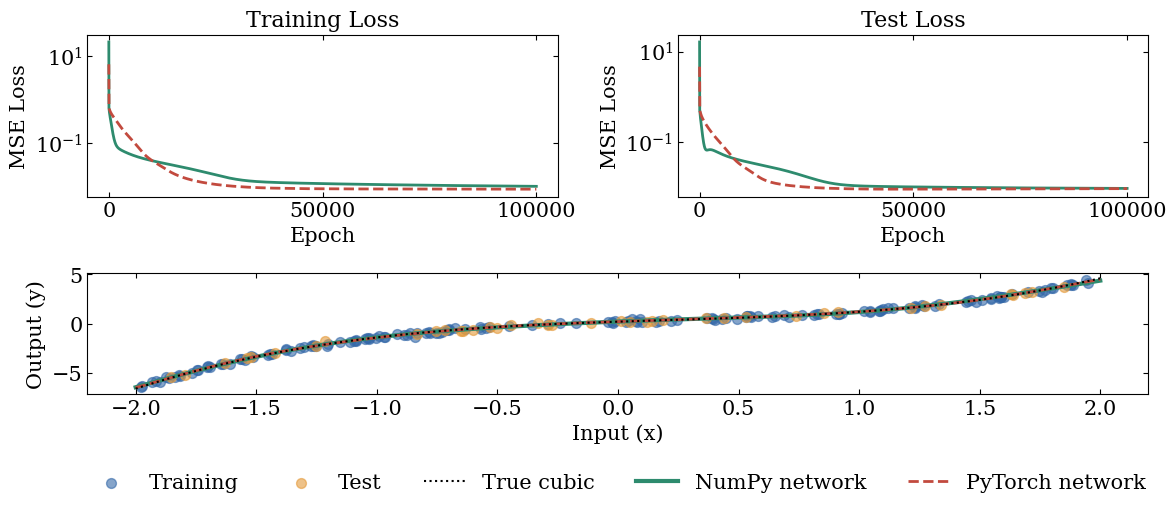

In [18]:
# Fitted function of the PyTorch network on the grid of inputs of the NumPy plot
X_plot_torch = torch.from_numpy(X_plot).float()
with torch.no_grad():  # Disable gradient computation for evaluation
    y_pred_plot_torch = pytorch_net(X_plot_torch).numpy()

# Create figure, the two losses in the top row and the fits below
fig = plt.figure(figsize=(12.4, 5.6))
grid = fig.add_gridspec(2, 2, height_ratios=[1, 0.75])
ax1 = fig.add_subplot(grid[0, 0])
ax2 = fig.add_subplot(grid[0, 1])
ax3 = fig.add_subplot(grid[1, :])

# Top panels, training loss and test loss of the two networks
for ax, numpy_loss, torch_loss, title in ((ax1, train_loss_history, pytorch_train_loss, 'Training Loss'),
                                         (ax2, test_loss_history, pytorch_test_loss, 'Test Loss')):
    ax.plot(numpy_loss, linewidth=2, color='C2', label='NumPy network')
    ax.plot(torch_loss, linewidth=2, linestyle='--', color='C3', label='PyTorch network')
    ax.set_xticks([0, 50000, 100000])  # Fewer ticks, so that the labels do not overlap
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE Loss')
    ax.set_yscale('log')
    ax.set_title(title)  # the legend of the bottom panel names the two networks

# Bottom panel, data and the fitted functions of the two networks
ax3.scatter(X_train, y_train, alpha=0.6, s=50, color='C0', label='Training')
ax3.scatter(X_test, y_test, alpha=0.6, s=50, color='C1', label='Test')

# True cubic polynomial, the highest power first in np.polyval
# It is drawn on top (zorder) of the fitted functions
ax3.plot(X_plot, np.polyval(coefficients, X_plot), ':', linewidth=1.5, color='black', zorder=3, label='True cubic')
ax3.plot(X_plot, y_pred_plot, linewidth=3, color='C2', label='NumPy network')
ax3.plot(X_plot, y_pred_plot_torch, linewidth=2, linestyle='--', color='C3', label='PyTorch network')
ax3.set_xlabel('Input (x)')
ax3.set_ylabel('Output (y)')
ax3.legend(loc='upper center', bbox_to_anchor=(0.5, -0.5), ncol=5)

plt.tight_layout()
plt.show()


Both networks fit the cubic, and both losses fall quickly at first and then slowly. The PyTorch training loss ends a little lower than the NumPy one, and the two test losses end almost equal. All final losses are close to the noise variance 0.01.

PyTorch differs from our NumPy network in four ways. It computes the backward pass for us, from the forward pass that we write. It provides ready-made layers, loss functions and optimizers. The same code runs on a GPU, a graphics processing unit, which is a processor built for matrix operations.

### Comparing Different Optimizers

PyTorch provides several optimizers, and we change one line to switch between them. We compare stochastic gradient descent with Adam (Section 15.3).

Stochastic gradient descent approximates the gradient with a small random subset of the training points, called a mini-batch. It shuffles the training points and splits them into mini-batches of a fixed size, such as 32. Each step uses the same update as before, with the loss $L_B$ of one mini-batch $B$ in place of the full loss $L$. The gradient of $L_B$ is a noisy estimate of the gradient of $L$.

A step costs less, so a large data set gives many steps in the time of one full pass. The noise can also help the weights to leave a shallow minimum. One epoch is a pass through all mini-batches. In PyTorch, `TensorDataset` pairs the inputs with their targets, and `DataLoader` shuffles them and delivers the mini-batches.

Adam adapts the step of each parameter in two ways.

- It keeps a moving average of the gradient. This is momentum, because the updates continue in the direction of the recent gradients and oscillations are damped.
- It keeps a moving average of the squared gradient, and it divides the step of each parameter by its square root. A parameter with consistent gradients then takes larger steps, and a parameter with highly variable gradients takes smaller steps.

We train two networks from the same initial weights for 2000 epochs with mini-batches of 32 points, so an epoch has five updates. After each epoch we compute two losses for all points. The training loss shows how fast each optimizer reduces the loss. The test loss shows how well the network predicts new points.

Gradient descent uses the learning rate 0.03 of the earlier runs, and Adam uses 0.01.


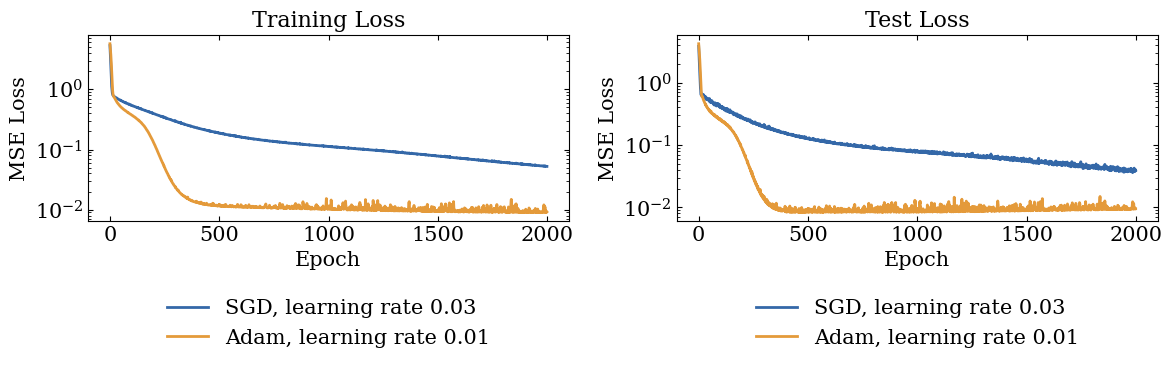

SGD, last 100 epochs: training 0.0545, test 0.0399
Adam, last 100 epochs: training 0.0094, test 0.0097


In [19]:
# Comparing SGD vs Adam optimizers
# Create two identical networks
net_sgd = PyTorchNetwork(input_dim=1, hidden_dim=20, output_dim=1)
net_adam = PyTorchNetwork(input_dim=1, hidden_dim=20, output_dim=1)

# Initialize with same weights for fair comparison
with torch.no_grad():
    # Copy weights from first network to the second
    net_adam.load_state_dict(net_sgd.state_dict())

# Define optimizers
optimizer_sgd = optim.SGD(net_sgd.parameters(), lr=0.03)
optimizer_adam = optim.Adam(net_adam.parameters(), lr=0.01)
nets = [('SGD', net_sgd, optimizer_sgd), ('Adam', net_adam, optimizer_adam)]

# A DataLoader delivers shuffled mini-batches of 32 points, the same for both networks
n_epochs_comparison = 2000
loader = DataLoader(TensorDataset(X_train_torch, y_train_torch), batch_size=32, shuffle=True)

def train_epoch(runs):
    """One epoch with mini-batches, one update of each network for every mini-batch."""
    for X_batch, y_batch in loader:
        for name, net, optimizer in runs:
            optimizer.zero_grad()  # Clear previous gradients
            loss = criterion(net(X_batch), y_batch)
            loss.backward()  # Compute gradients
            optimizer.step()  # Update parameters

def full_losses(net):
    """Training and test loss of all points."""
    with torch.no_grad():
        return (criterion(net(X_train_torch), y_train_torch).item(),
                criterion(net(X_test_torch), y_test_torch).item())

train_losses = {'SGD': [], 'Adam': []}
test_losses = {'SGD': [], 'Adam': []}
for epoch in range(n_epochs_comparison):
    train_epoch(nets)
    for name, net, optimizer in nets:
        train, test = full_losses(net)  # Losses after the epoch
        train_losses[name].append(train)
        test_losses[name].append(test)

# Plot the training loss and the test loss
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, losses, title in ((ax1, train_losses, 'Training Loss'), (ax2, test_losses, 'Test Loss')):
    ax.plot(losses['SGD'], linewidth=2, color='C0', label='SGD, learning rate 0.03')
    ax.plot(losses['Adam'], linewidth=2, color='C1', label='Adam, learning rate 0.01')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE Loss')
    ax.set_yscale('log')
    ax.set_title(title)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.32), ncol=1)
plt.tight_layout()
plt.show()

# Print the mean losses of the last 100 epochs
for name in train_losses:
    print(f"{name}, last 100 epochs: "
          f"training {np.mean(train_losses[name][-100:]):.4f}, test {np.mean(test_losses[name][-100:]):.4f}")


### Understanding the Optimizer Comparison

With these settings, Adam reaches a far lower training and test loss than gradient descent in the same number of epochs. In the plot, both losses fall together until about epoch 60. Then the loss of gradient descent falls slowly and steadily, because its step is proportional to the gradient and the gradient is small. Adam divides the step by the root mean square of the recent gradients. Its step does not shrink in the same way, and its loss reaches the noise level of the data after about 500 epochs.

Both optimizers use a different mini-batch for each update, so both losses fluctuate. The fluctuation of Adam is larger, because its steps stay large.

After 2000 epochs the test loss of gradient descent is still about four times the noise variance. The test loss of Adam is close to the noise variance.

### Learning Rate Schedules

Each optimizer above used one fixed learning rate. A fixed rate is a compromise. A large rate makes fast progress at the start, but it makes the weights jump around the minimum at the end. A small rate is precise, but it is slow. A learning rate schedule changes the rate during the training (Section 7.8).

Cosine annealing lowers the learning rate from $\eta_0$ to a minimum $\eta_{\rm min}$ along a cosine curve over a cycle of $T$ steps,

$$\eta^{(\tau)} = \eta_{\rm min} + \frac{1}{2}(\eta_0 - \eta_{\rm min})\left(1 + \cos\frac{\tau\pi}{T}\right),$$

where $\tau$ counts the steps since the start of the cycle. The curve falls slowly at first, fastest in the middle and slowly again at the end. At the end of a cycle the rate returns to $\eta_0$, and a new cycle starts. The name comes from annealing in metallurgy, where a metal that is cooled slowly settles into an ordered structure. The high rates explore the parameter space, and the low rates improve the solution.

PyTorch provides this schedule as `optim.lr_scheduler.CosineAnnealingWarmRestarts`. The argument `T_0` is the length of the first cycle in epochs, and `eta_min` is the minimum rate. The scheduler takes $\eta_0$ from the learning rate of the optimizer. It changes the rate each time that we call `scheduler.step()`, which we do once after each epoch.

We train two networks from the same initial weights with Adam for 2000 epochs, with the mini-batches of the last section. One keeps the learning rate 0.01. The other uses cycles of 500 epochs, from 0.01 down to 0.0001. The left panel shows the two learning rates. The right panel shows the training losses as solid lines and the test losses as dashed lines. We also print the final losses of each network.

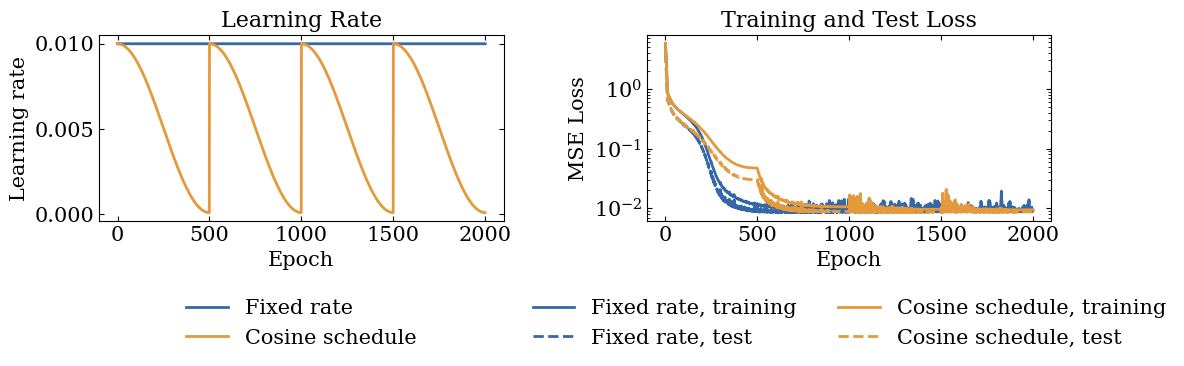

Fixed rate, last 100 epochs: training 0.0097, test 0.0094
Cosine schedule, last 100 epochs: training 0.0094, test 0.0087


In [20]:
# Two identical networks with the same initial weights
net_fixed = PyTorchNetwork(input_dim=1, hidden_dim=20, output_dim=1)
net_cosine = PyTorchNetwork(input_dim=1, hidden_dim=20, output_dim=1)
net_cosine.load_state_dict(net_fixed.state_dict())

# Adam with a fixed rate, and Adam with cosine cycles of 500 epochs from 0.01 to 0.0001
optimizer_fixed = optim.Adam(net_fixed.parameters(), lr=0.01)
optimizer_cosine = optim.Adam(net_cosine.parameters(), lr=0.01)

# The scheduler lowers the rate of the cosine run along cosine cycles of T_0 epochs, and each cycle restarts at the start rate
scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer_cosine, T_0=500, eta_min=0.0001)

# Train both networks with the mini-batches of the last section, and record the losses and the learning rate
runs = [('Fixed rate', net_fixed, optimizer_fixed), ('Cosine schedule', net_cosine, optimizer_cosine)]
train_schedule = {name: [] for name, _, _ in runs}
test_schedule = {name: [] for name, _, _ in runs}
rates = {name: [] for name, _, _ in runs}
for epoch in range(n_epochs_comparison):
    for name, _, optimizer in runs:
        rates[name].append(optimizer.param_groups[0]['lr'])
    train_epoch(runs)
    for name, net, optimizer in runs:
        train, test = full_losses(net)  # Losses after the epoch
        train_schedule[name].append(train)
        test_schedule[name].append(test)

    # Change the learning rate of the cosine run for the next epoch
    scheduler.step()

# Plot the learning rates and the losses, the training loss solid and the test loss dashed
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
for color, name in zip(('C0', 'C1'), rates):
    ax1.plot(rates[name], linewidth=2, color=color, label=name)
    ax2.plot(train_schedule[name], linewidth=2, color=color, label=f"{name}, training")
    ax2.plot(test_schedule[name], linewidth=2, linestyle='--', color=color, label=f"{name}, test")
ax1.set_ylabel('Learning rate')
ax1.set_title('Learning Rate')
ax2.set_ylabel('MSE Loss')
ax2.set_yscale('log')
ax2.set_title('Training and Test Loss')
for ax, columns in ((ax1, 1), (ax2, 2)):
    ax.set_xlabel('Epoch')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.32), ncol=columns)
plt.tight_layout()
plt.show()

# Print the mean losses of the last 100 epochs
for name in train_schedule:
    print(f"{name}, last 100 epochs: "
          f"training {np.mean(train_schedule[name][-100:]):.4f}, test {np.mean(test_schedule[name][-100:]):.4f}")


The learning rate of the cosine run falls in four cycles and jumps back to 0.01 at each restart. In the first cycle its loss falls more slowly than that of the fixed rate, because its rate is lower. At the end of each cycle, when the rate is small, its loss is smooth. The loss of the fixed rate keeps fluctuating because of the mini-batches, and the loss of the cosine run fluctuates again after a restart.

The two runs end at about the same training loss. The test loss of the cosine run is a little lower, 0.0087 against 0.0094 in the means of the last 100 epochs. The gain is small for this simple problem. Annealing removes the noise of the mini-batches at the end of a cycle, and this matters more for problems with many minima. Tutorial 15d uses one cycle of a cosine decay for a larger network.

### Activation Functions and Initialization in PyTorch

The hidden units of our networks used the sigmoid. The sigmoid saturates, so its gradient becomes small for large inputs, which is the vanishing gradient problem above. Most networks therefore use the Rectified Linear Unit (ReLU) or the Gaussian Error Linear Unit (GELU) in their hidden layers (Section 15.5).

ReLU is $\max(0, x)$. GELU is $x\,\Phi(x)$, where $\Phi$ is the cumulative distribution function of the standard normal distribution. PyTorch provides them as `nn.ReLU()` and `nn.GELU()`, and we switch between them by changing one line of the network. We print the three functions at five inputs.

In [21]:
# The sigmoid, ReLU and GELU at five inputs
x_values = torch.tensor([-2.0, -1.0, 0.0, 1.0, 2.0])
for name, activation in (("Sigmoid", nn.Sigmoid()), ("ReLU", nn.ReLU()), ("GELU", nn.GELU())):
    print(f"{name:8s}", np.round(activation(x_values).numpy(), 3))

Sigmoid  [0.119 0.269 0.5   0.731 0.881]
ReLU     [0. 0. 0. 1. 2.]
GELU     [-0.046 -0.159  0.     0.841  1.954]


ReLU is zero for negative inputs and equal to the input for positive inputs. Its gradient is 1 for positive inputs, so it does not shrink as the gradient of the sigmoid does. GELU is smooth near zero and approaches ReLU for large inputs.

The initial weights matter too, although the textbook does not cover them. If they are too small, the signal shrinks from layer to layer, and if they are too large, it grows. The He initialization, also called Kaiming initialization, draws the weights of a layer with the standard deviation $\sqrt{2/n_{\rm in}}$. Here $n_{\rm in}$ is the number of inputs of the layer.

ReLU sets about half of the values to zero, which halves the variance of the signal, and the factor 2 compensates for this. In PyTorch, `nn.init.kaiming_normal_` applies it to the weights of a layer. The cell passes random inputs through a ReLU network of 20 layers with 100 units each. It repeats this for the weight variances $1/n_{\rm in}$, $2/n_{\rm in}$ and $4/n_{\rm in}$, and it prints the standard deviation of the output.

In [22]:
# The size of the output of a 20-layer ReLU network for three weight scales
_ = torch.manual_seed(0)
n_units = 100
inputs = torch.randn(1000, n_units)

for name, factor in (("Variance 1/n_in", 1.0), ("He, 2/n_in", 2.0), ("Variance 4/n_in", 4.0)):
    signal = inputs
    for layer in range(20):
        # Random weights with the variance factor/n_in
        weights = torch.randn(n_units, n_units) * np.sqrt(factor / n_units)
        signal = torch.relu(signal @ weights)
    print(f"{name}: standard deviation of the output = {signal.std():.3g}")

Variance 1/n_in: standard deviation of the output = 0.000391
He, 2/n_in: standard deviation of the output = 0.776
Variance 4/n_in: standard deviation of the output = 519


With the variance $1/n_{\rm in}$ the output shrinks to almost zero after 20 layers, and with $4/n_{\rm in}$ it grows by orders of magnitude. The He scale keeps the output at a size similar to the input. The factor 2 belongs to ReLU. A sigmoid layer keeps its output between 0 and 1 for any scale of the weights. The sigmoid networks above therefore did not need it, and they used the default of `nn.Linear`. The He initialization matters for deep ReLU networks.

### GPU Acceleration in PyTorch

So far all computations ran on the CPU. A GPU runs the matrix operations of a network much faster (Section 15.4), which helps large models. To use a GPU we move the model and the data to the device with `.to(device)`, where `device` names the GPU or the CPU.

The rest of the code stays the same, and we move results back to the CPU before NumPy or matplotlib use them. We move the model and the data to the device, run a forward pass and move the result back. This runs on the CPU when no GPU is available.

In [23]:
# Use a GPU when one is available, and the CPU otherwise
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Move the network and the training data to the device
model = PyTorchNetwork(input_dim=1, hidden_dim=20, output_dim=1).to(device)
X_train_device = X_train_torch.to(device)

# The forward pass, the backward pass and the update then run on the device
y_pred_device = model(X_train_device)

# Move results back to the CPU before NumPy or matplotlib use them
y_pred_cpu = y_pred_device.detach().cpu().numpy()
print(f"Device: {device}, predictions on the CPU with shape {y_pred_cpu.shape}")


Device: cpu, predictions on the CPU with shape (160, 1)


## Summary

In this tutorial we went from backpropagation in NumPy to the automatic differentiation of PyTorch. Our main lessons follow.

1. **Backpropagation.** The forward pass stores the intermediate values. The backward pass multiplies the local derivatives with the chain rule, from the loss back to each parameter. One backward pass gives the gradient with respect to all parameters.
2. **Automatic differentiation.** It differs from symbolic differentiation, which builds a formula, and from finite differences, which need one extra forward pass for each parameter. PyTorch records each operation on tensors that require gradients in a computational graph. We write the forward pass, and the library supplies the backward pass. The same code runs on a GPU after the model and the data move there.
3. **Optimizers.** Gradient descent steps along the scaled gradient with one learning rate. Adam sets the step of each parameter from the history of its gradients. Stochastic gradient descent uses the gradient of a random mini-batch in place of all points. A schedule such as cosine annealing changes the rate during the training.
4. **Activations and initialization.** ReLU and GELU replace the sigmoid in the hidden layers of most networks. The He initialization scales the weights of a ReLU layer by $\sqrt{2/n_{\rm in}}$, which keeps the size of the signal the same from layer to layer.

The chain rule, the forward and backward passes and a gradient-based optimizer are most of what even very complex models need. PyTorch supplies the backward pass and modules, which lowers the barrier to building them.